<a href="https://colab.research.google.com/github/rachana1707-S/Adaptive-MedRAG/blob/feature%2Frachana-retrieval/notebooks/01_retrieval.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Installing the libraries needed for my retrieval experiments
# huggingface_hub will help me download NFCorpus
# rank-bm25 will be used for the BM25 baseline

!pip -q install huggingface_hub pandas pyarrow numpy rank-bm25

In [ ]:
# Importing the libraries that I will use in this notebook

import re
import time

from pathlib import Path

import numpy as np
import pandas as pd

from huggingface_hub import hf_hub_download
from rank_bm25 import BM25Okapi

In [ ]:
# Creating folders to store the dataset and experiment results

DATA_DIR = Path("data/nfcorpus")
RESULTS_DIR = Path("results")

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Folders created successfully!")

Folders created successfully!


In [ ]:
# Downloading the documents, queries, and test labels
# from Hugging Face instead of the original BEIR server

corpus_path = hf_hub_download(
    repo_id="BeIR/nfcorpus",
    filename="corpus/corpus-00000-of-00001.parquet",
    repo_type="dataset"
)

queries_path = hf_hub_download(
    repo_id="BeIR/nfcorpus",
    filename="queries/queries-00000-of-00001.parquet",
    repo_type="dataset"
)

qrels_path = hf_hub_download(
    repo_id="BeIR/nfcorpus-qrels",
    filename="test.tsv",
    repo_type="dataset"
)

print("All NFCorpus files downloaded successfully!")

All NFCorpus files downloaded successfully!


In [ ]:
# Loading the dataset files into pandas DataFrames

corpus_df = pd.read_parquet(corpus_path)
queries_df = pd.read_parquet(queries_path)
qrels_df = pd.read_csv(qrels_path, sep="\t")

# Checking the number of documents and queries

print("Total documents:", len(corpus_df))
print("Total queries:", len(queries_df))
print("Total relevance labels:", len(qrels_df))

Total documents: 3633
Total queries: 3237
Total relevance labels: 12334


In [ ]:
# Looking at the column names before preprocessing the data

print("Corpus columns:", corpus_df.columns.tolist())
print("Query columns:", queries_df.columns.tolist())
print("Qrels columns:", qrels_df.columns.tolist())

# Displaying some documents and queries

display(corpus_df.head(3))
display(queries_df.head(3))
display(qrels_df.head(3))

Corpus columns: ['_id', 'title', 'text']
Query columns: ['_id', 'title', 'text']
Qrels columns: ['query-id', 'corpus-id', 'score']


,_id,title,text
0,MED-10,Statin Use and Breast Cancer Survival: A Natio...,"Recent studies have suggested that statins, an..."
1,MED-14,Statin use after diagnosis of breast cancer an...,BACKGROUND: Preclinical studies have shown tha...
2,MED-118,Alkylphenols in human milk and their relations...,The aims of this study were to determine the c...


,_id,title,text
0,PLAIN-3,,Breast Cancer Cells Feed on Cholesterol
1,PLAIN-4,,Using Diet to Treat Asthma and Eczema
2,PLAIN-5,,Treating Asthma With Plants vs. Pills


,query-id,corpus-id,score
0,PLAIN-2,MED-2427,2
1,PLAIN-2,MED-10,2
2,PLAIN-2,MED-2429,2


In [ ]:
# Using document and query IDs to access the data easily

corpus = {
    str(row["_id"]): {
        "title": str(row["title"] or ""),
        "text": str(row["text"] or "")
    }
    for _, row in corpus_df.fillna("").iterrows()
}

queries = {
    str(row["_id"]): str(row["text"])
    for _, row in queries_df.iterrows()
}

print("Corpus size:", len(corpus))
print("Queries loaded:", len(queries))

Corpus size: 3633
Queries loaded: 3237


In [ ]:
# Creating a tokenizer to split the text into words
# Converting everything to lowercase so matching is consistent

import re

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

In [ ]:
# Getting all the document IDs from our corpus

doc_ids = list(corpus.keys())

# Combining the title and text of each document

doc_texts = []

for doc_id in doc_ids:
    title = corpus[doc_id]["title"]
    text = corpus[doc_id]["text"]

    combined_text = title + " " + text
    doc_texts.append(combined_text)

print("Total documents:", len(doc_texts))

Total documents: 3633


In [ ]:
# Tokenizing all documents before building the BM25 index

tokenized_corpus = []

for text in doc_texts:
    tokens = tokenize(text)
    tokenized_corpus.append(tokens)

# Checking how the first document looks after tokenization

print("First 20 tokens:")
print(tokenized_corpus[0][:20])

First 20 tokens:
['statin', 'use', 'and', 'breast', 'cancer', 'survival', 'a', 'nationwide', 'cohort', 'study', 'from', 'finland', 'recent', 'studies', 'have', 'suggested', 'that', 'statins', 'an', 'established']


In [ ]:
# Importing the BM25 library

from rank_bm25 import BM25Okapi

# Building the BM25 index using the tokenized documents

bm25 = BM25Okapi(tokenized_corpus)

print("BM25 model created successfully!")

BM25 model created successfully!


In [ ]:
# This function searches the corpus using BM25
# It returns the top k documents for a given question

import numpy as np

def bm25_search(query, top_k=5):

    # Tokenizing the user's question
    query_tokens = tokenize(query)

    # Getting BM25 scores for all documents
    scores = bm25.get_scores(query_tokens)

    # Sorting documents by their scores
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    # Collecting the top documents and their scores
    for rank, idx in enumerate(top_indices, start=1):

        doc_id = doc_ids[idx]

        results.append({
            "doc_id": doc_id,
            "chunk_id": None,
            "score": float(scores[idx]),
            "rank": rank,
            "title": corpus[doc_id]["title"],
            "text": corpus[doc_id]["text"]
        })

    return results

In [ ]:
# Testing our retrieval function with a medical question

question = "What are the health benefits of dietary fiber?"

results = bm25_search(question, top_k=5)

# Displaying the retrieved documents

for result in results:

    print("Rank:", result["rank"])
    print("Document ID:", result["doc_id"])
    print("BM25 Score:", round(result["score"], 4))
    print("Title:", result["title"])
    print("Text:", result["text"][:200])
    print("-" * 50)

Rank: 1
Document ID: MED-2291
BM25 Score: 22.3933
Title: Viscous versus nonviscous soluble fiber supplements: mechanisms and evidence for fiber-specific health benefits.
Text: PURPOSE: This review focuses on the health benefits of viscous versus nonviscous soluble fibers, why symptoms can occur with increased fiber consumption, and how to avoid symptoms to improve adherence
--------------------------------------------------
Rank: 2
Document ID: MED-1374
BM25 Score: 21.6928
Title: Definitions and potential health benefits of the Mediterranean diet: views from experts around the world
Text: The Mediterranean diet has been linked to a number of health benefits, including reduced mortality risk and lower incidence of cardiovascular disease. Definitions of the Mediterranean diet vary across
--------------------------------------------------
Rank: 3
Document ID: MED-973
BM25 Score: 21.2251
Title: What is a high fiber diet?
Text: There is no recognized definition of what constitutes a high fi

In [ ]:
# Selecting a question from the official test set

test_query_id = str(qrels_df["query-id"].iloc[0])

question = queries[test_query_id]

print("Query ID:", test_query_id)
print("Question:", question)

# Retrieving the top 5 documents

results = bm25_search(question, top_k=5)

for result in results:
    print(
        "Rank:", result["rank"],
        "| Document:", result["doc_id"],
        "| Score:", round(result["score"], 4)
    )

Query ID: PLAIN-2
Question: Do Cholesterol Statin Drugs Cause Breast Cancer?
Rank: 1 | Document: MED-14 | Score: 21.3211
Rank: 2 | Document: MED-2429 | Score: 21.2539
Rank: 3 | Document: MED-10 | Score: 19.329
Rank: 4 | Document: MED-2428 | Score: 19.1221
Rank: 5 | Document: MED-1193 | Score: 18.4465


In [ ]:
# Saving the retrieved results so we can inspect them later

import pandas as pd

sample_results_df = pd.DataFrame(results)

sample_results_df.to_csv(
    RESULTS_DIR / "bm25_sample_results.csv",
    index=False
)

print("Sample BM25 results saved!")

Sample BM25 results saved!


In [ ]:
# Downloading sample results to save them in our repository

from google.colab import files

files.download("results/bm25_sample_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Checking the relevance labels from NFCorpus
# These labels show which documents are relevant to each query

print("Qrels columns:", qrels_df.columns.tolist())

print("Total relevance entries:", len(qrels_df))

print("Number of test queries:", qrels_df["query-id"].nunique())

display(qrels_df.head())

Qrels columns: ['query-id', 'corpus-id', 'score']
Total relevance entries: 12334
Number of test queries: 323


,query-id,corpus-id,score
0,PLAIN-2,MED-2427,2
1,PLAIN-2,MED-10,2
2,PLAIN-2,MED-2429,2
3,PLAIN-2,MED-2430,2
4,PLAIN-2,MED-2431,2


In [ ]:
# Creating a dictionary to store relevant documents for each query
# We will use this to compare against the BM25 search results

qrels = {}

for _, row in qrels_df.iterrows():

    query_id = str(row["query-id"])
    doc_id = str(row["corpus-id"])
    relevance = int(row["score"])

    # Only keeping documents with positive relevance scores
    if relevance > 0:

        if query_id not in qrels:
            qrels[query_id] = {}

        qrels[query_id][doc_id] = relevance

print("Queries with relevant documents:", len(qrels))

Queries with relevant documents: 323


In [ ]:
# Checking one query and its relevant documents

sample_query_id = list(qrels.keys())[0]

print("Query ID:", sample_query_id)
print("Question:", queries[sample_query_id])

print("\nRelevant documents:")
print(qrels[sample_query_id])

Query ID: PLAIN-2
Question: Do Cholesterol Statin Drugs Cause Breast Cancer?

Relevant documents:
{'MED-2427': 2, 'MED-10': 2, 'MED-2429': 2, 'MED-2430': 2, 'MED-2431': 2, 'MED-14': 2, 'MED-2432': 2, 'MED-2428': 1, 'MED-2440': 1, 'MED-2434': 1, 'MED-2435': 1, 'MED-2436': 1, 'MED-2437': 1, 'MED-2438': 1, 'MED-2439': 1, 'MED-3597': 1, 'MED-3598': 1, 'MED-3599': 1, 'MED-4556': 1, 'MED-4559': 1, 'MED-4560': 1, 'MED-4828': 1, 'MED-4829': 1, 'MED-4830': 1}


In [ ]:
# Recall@k measures how many relevant documents we found
# out of all relevant documents for a query

def recall_at_k(retrieved_ids, relevant_docs, k):

    relevant_ids = set(relevant_docs.keys())

    if len(relevant_ids) == 0:
        return 0.0

    # Taking only the top k retrieved documents
    top_k_ids = set(retrieved_ids[:k])

    # Counting how many retrieved documents are relevant
    relevant_found = len(top_k_ids.intersection(relevant_ids))

    recall = relevant_found / len(relevant_ids)

    return recall

In [ ]:
# nDCG measures the quality of the document ranking
# It gives more importance to relevant documents near the top

def ndcg_at_k(retrieved_ids, relevant_docs, k):

    # Calculating DCG for the documents returned by BM25
    dcg = 0.0

    for rank, doc_id in enumerate(retrieved_ids[:k]):

        relevance = relevant_docs.get(doc_id, 0)

        dcg += (2 ** relevance - 1) / np.log2(rank + 2)

    # Calculating the best possible ranking score
    ideal_scores = sorted(
        relevant_docs.values(),
        reverse=True
    )[:k]

    idcg = 0.0

    for rank, relevance in enumerate(ideal_scores):

        idcg += (2 ** relevance - 1) / np.log2(rank + 2)

    # Avoiding division by zero
    if idcg == 0:
        return 0.0

    return dcg / idcg

In [ ]:
# Testing our evaluation functions with a small example
# We know the expected results, so this checks our calculations

sample_relevant = {
    "doc_A": 2,
    "doc_B": 1
}

sample_retrieved = [
    "doc_A",
    "doc_C",
    "doc_B"
]

print("Recall@2:", recall_at_k(
    sample_retrieved, sample_relevant, 2
))

print("Recall@3:", recall_at_k(
    sample_retrieved, sample_relevant, 3
))

print("nDCG@3:", round(ndcg_at_k(
    sample_retrieved, sample_relevant, 3
), 4))

assert recall_at_k(sample_retrieved, sample_relevant, 2) == 0.5
assert recall_at_k(sample_retrieved, sample_relevant, 3) == 1.0
assert 0 <= ndcg_at_k(sample_retrieved, sample_relevant, 3) <= 1

print("Metric checks passed!")

Recall@2: 0.5
Recall@3: 1.0
nDCG@3: 0.9639
Metric checks passed!


In [ ]:
# Running BM25 on all NFCorpus test queries
# For each query, we calculate recall, nDCG, and search time

evaluation_results = []

for query_id, relevant_docs in qrels.items():

    if query_id not in queries:
        continue

    question = queries[query_id]

    # Measuring the time taken by BM25 search
    start_time = time.perf_counter()

    results = bm25_search(question, top_k=10)

    search_time = (time.perf_counter() - start_time) * 1000

    # Getting the document IDs returned by BM25
    retrieved_ids = [result["doc_id"] for result in results]

    # Storing the metrics for this query
    evaluation_results.append({
        "query_id": query_id,
        "recall_5": recall_at_k(
            retrieved_ids, relevant_docs, 5
        ),
        "recall_10": recall_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "ndcg_10": ndcg_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "search_time_ms": search_time
    })

evaluation_df = pd.DataFrame(evaluation_results)

print("Total queries evaluated:", len(evaluation_df))

display(evaluation_df.head())

Total queries evaluated: 323


,query_id,recall_5,recall_10,ndcg_10,search_time_ms
0,PLAIN-2,0.166667,0.333333,0.795267,33.911384
1,PLAIN-12,0.000000,0.000000,0.000000,57.209029
2,PLAIN-23,0.033333,0.044444,0.178186,39.793412
3,PLAIN-33,0.031250,0.031250,0.098987,22.582643
4,PLAIN-44,0.000000,0.000000,0.000000,20.581687


In [ ]:
# Calculating the average retrieval performance
# across all the test queries

summary = evaluation_df[
    ["recall_5", "recall_10", "ndcg_10", "search_time_ms"]
].mean()

print("BM25 Baseline Evaluation")
print("------------------------")

print("Recall@5:", round(summary["recall_5"], 4))
print("Recall@10:", round(summary["recall_10"], 4))
print("nDCG@10:", round(summary["ndcg_10"], 4))
print("Average search time (ms):",
      round(summary["search_time_ms"], 4))

BM25 Baseline Evaluation
------------------------
Recall@5: 0.115
Recall@10: 0.1521
nDCG@10: 0.3071
Average search time (ms): 16.996


In [ ]:
# Saving the results for every test query
# We will use them later when comparing retrieval methods

from pathlib import Path

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

evaluation_df.to_csv(
    RESULTS_DIR / "bm25_per_query.csv",
    index=False
)

print("Per-query results saved!")

Per-query results saved!


In [ ]:
# Saving the average BM25 metrics in a separate CSV file

summary_df = summary.reset_index()

summary_df.columns = ["metric", "value"]

summary_df.to_csv(
    RESULTS_DIR / "bm25_summary.csv",
    index=False
)

display(summary_df)

print("BM25 summary saved!")

,metric,value
0,recall_5,0.115050
1,recall_10,0.152143
2,ndcg_10,0.307062
3,search_time_ms,16.995994


BM25 summary saved!


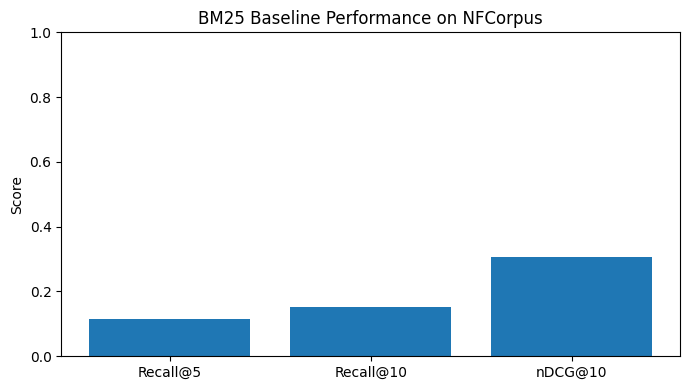

In [ ]:
# Plotting the BM25 evaluation scores
# This graph will help us compare methods later

import matplotlib.pyplot as plt

metrics = ["Recall@5", "Recall@10", "nDCG@10"]

values = [
    summary["recall_5"],
    summary["recall_10"],
    summary["ndcg_10"]
]

plt.figure(figsize=(7, 4))

plt.bar(metrics, values)

plt.title("BM25 Baseline Performance on NFCorpus")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "bm25_metrics.png", dpi=150)

plt.show()

In [ ]:
# Downloading my BM25 evaluation results
# These files will also be added to our GitHub repository

from google.colab import files

files.download("results/bm25_per_query.csv")
files.download("results/bm25_summary.csv")
files.download("results/bm25_metrics.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Installing the library for generating text embeddings
# We will use a pretrained model for dense retrieval

!pip -q install -U sentence-transformers

In [ ]:
# Importing the libraries needed for dense retrieval

import time
import numpy as np
import pandas as pd

from pathlib import Path
from sentence_transformers import SentenceTransformer

In [ ]:
# Loading a pretrained Sentence Transformer model
# This model converts text into numerical vectors

model_name = "sentence-transformers/all-MiniLM-L6-v2"

embedding_model = SentenceTransformer(model_name)

print("Embedding model loaded successfully!")
print("Model:", model_name)
print("Embedding size:",
      embedding_model.get_sentence_embedding_dimension())

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embedding model loaded successfully!
Model: sentence-transformers/all-MiniLM-L6-v2
Embedding size: 384


/tmp/ipykernel_386/2223766747.py:11: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_model.get_sentence_embedding_dimension())


In [ ]:
# Checking that the documents from Part 2 are available
# We are using whole documents for this baseline

print("Total documents:", len(doc_texts))
print("Total document IDs:", len(doc_ids))

print("\nSample document:")
print(doc_texts[0][:300])

assert len(doc_texts) == len(doc_ids)

Total documents: 3633
Total document IDs: 3633

Sample document:
Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains uncl


In [ ]:
# Converting all the documents into dense vectors
# Normalizing the vectors helps us calculate cosine similarity

start_time = time.perf_counter()

document_embeddings = embedding_model.encode_document(
    doc_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embedding_time = time.perf_counter() - start_time

print("Document embeddings created!")
print("Shape:", document_embeddings.shape)
print("Embedding time (seconds):", round(embedding_time, 2))

Batches:   0%|          | 0/114 [00:00<?, ?it/s]

Document embeddings created!
Shape: (3633, 384)
Embedding time (seconds): 471.75


In [ ]:
# Saving the embeddings so we do not need to
# generate them again during the same experiment setup

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

np.save(
    RESULTS_DIR / "dense_embeddings.npy",
    document_embeddings
)

# Saving document IDs in their original embedding order
pd.DataFrame({"doc_id": doc_ids}).to_csv(
    RESULTS_DIR / "dense_document_ids.csv",
    index=False
)

print("Embeddings and document IDs saved!")

Embeddings and document IDs saved!


In [ ]:
# This function searches for documents using semantic similarity
# It compares the question embedding with all document embeddings

def dense_search(query, top_k=5):

    # Converting the question into an embedding
    query_embedding = embedding_model.encode_query(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    # Calculating similarity with all the documents
    # Since the embeddings are normalized, dot product
    # gives the cosine similarity
    scores = document_embeddings @ query_embedding

    # Getting the top k documents with the highest scores
    top_indices = np.argsort(scores)[::-1][:top_k]

    results = []

    for rank, idx in enumerate(top_indices, start=1):

        doc_id = doc_ids[idx]

        results.append({
            "doc_id": doc_id,
            "chunk_id": None,
            "score": float(scores[idx]),
            "rank": rank,
            "title": corpus[doc_id]["title"],
            "text": corpus[doc_id]["text"]
        })

    return results

In [ ]:
# Testing dense retrieval with a medical question

question = "What are the benefits of dietary fiber?"

results = dense_search(question, top_k=5)

for result in results:

    print("Rank:", result["rank"])
    print("Document ID:", result["doc_id"])
    print("Similarity Score:", round(result["score"], 4))
    print("Title:", result["title"])
    print("Text:", result["text"][:200])
    print("-" * 50)

Rank: 1
Document ID: MED-1234
Similarity Score: 0.6162
Title: Cardiovascular benefits of dietary fiber.
Text: The relationship between dietary fiber and risk of cardiovascular disease (CVD) has been extensively studied. There is considerable epidemiological evidence indicating an inverse association between d
--------------------------------------------------
Rank: 2
Document ID: MED-2529
Similarity Score: 0.6127
Title: Effect of a very-high-fiber vegetable, fruit, and nut diet on serum lipids and colonic function.
Text: We tested the effects of feeding a diet very high in fiber from fruit and vegetables. The levels fed were those, which had originally inspired the dietary fiber hypothesis related to colon cancer and 
--------------------------------------------------
Rank: 3
Document ID: MED-2293
Similarity Score: 0.6039
Title: Dietary Fiber Future Directions: Integrating New Definitions and Findings to Inform Nutrition Research and Communication
Text: The CODEX Alimentarius definitio

In [ ]:
# Comparing the top documents from BM25 and dense retrieval

question = "What are the health benefits of a plant-based diet?"

bm25_results = bm25_search(question, top_k=5)
dense_results = dense_search(question, top_k=5)

comparison_df = pd.DataFrame({
    "Rank": [1, 2, 3, 4, 5],
    "BM25 Document": [r["doc_id"] for r in bm25_results],
    "Dense Document": [r["doc_id"] for r in dense_results]
})

display(comparison_df)

,Rank,BM25 Document,Dense Document
0,1,MED-1374,MED-1991
1,2,MED-4831,MED-4831
2,3,MED-1997,MED-4255
3,4,MED-2335,MED-4613
4,5,MED-3931,MED-4349


In [ ]:
# Evaluating dense retrieval using the NFCorpus test queries
# Using the same metrics as our BM25 experiment

dense_evaluation_results = []

for query_id, relevant_docs in qrels.items():

    if query_id not in queries:
        continue

    question = queries[query_id]

    # Starting the timer before searching
    start_time = time.perf_counter()

    results = dense_search(question, top_k=10)

    search_time = (time.perf_counter() - start_time) * 1000

    # Collecting retrieved document IDs
    retrieved_ids = [
        result["doc_id"]
        for result in results
    ]

    # Calculating retrieval metrics
    dense_evaluation_results.append({
        "query_id": query_id,
        "recall_5": recall_at_k(
            retrieved_ids, relevant_docs, 5
        ),
        "recall_10": recall_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "ndcg_10": ndcg_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "search_time_ms": search_time
    })

dense_evaluation_df = pd.DataFrame(
    dense_evaluation_results
)

print("Queries evaluated:", len(dense_evaluation_df))
display(dense_evaluation_df.head())

Queries evaluated: 323


,query_id,recall_5,recall_10,ndcg_10,search_time_ms
0,PLAIN-2,0.166667,0.375000,0.769390,25.628343
1,PLAIN-12,0.033333,0.066667,0.115672,23.118083
2,PLAIN-23,0.033333,0.044444,0.344357,26.058528
3,PLAIN-33,0.031250,0.093750,0.256615,23.739498
4,PLAIN-44,0.017241,0.051724,0.237448,23.305731


In [ ]:
# Calculating the average metrics across the test queries

dense_summary = dense_evaluation_df[
    ["recall_5", "recall_10", "ndcg_10", "search_time_ms"]
].mean()

print("Dense Retrieval Results")
print("-----------------------")

print("Recall@5:", round(dense_summary["recall_5"], 4))
print("Recall@10:", round(dense_summary["recall_10"], 4))
print("nDCG@10:", round(dense_summary["ndcg_10"], 4))
print("Average search time:",
      round(dense_summary["search_time_ms"], 2), "ms")

Dense Retrieval Results
-----------------------
Recall@5: 0.1197
Recall@10: 0.155
nDCG@10: 0.3169
Average search time: 26.07 ms


In [ ]:
# Saving dense retrieval metrics for our final comparison

dense_evaluation_df.to_csv(
    RESULTS_DIR / "dense_per_query.csv",
    index=False
)

dense_summary_df = dense_summary.reset_index()
dense_summary_df.columns = ["metric", "value"]

dense_summary_df.to_csv(
    RESULTS_DIR / "dense_summary.csv",
    index=False
)

print("Dense retrieval results saved!")

Dense retrieval results saved!


In [ ]:
# Comparing the average results from BM25 and dense retrieval

comparison = pd.DataFrame({
    "Metric": [
        "Recall@5",
        "Recall@10",
        "nDCG@10",
        "Search Time (ms)"
    ],
    "BM25": [
        summary["recall_5"],
        summary["recall_10"],
        summary["ndcg_10"],
        summary["search_time_ms"]
    ],
    "Dense": [
        dense_summary["recall_5"],
        dense_summary["recall_10"],
        dense_summary["ndcg_10"],
        dense_summary["search_time_ms"]
    ]
})

display(comparison.round(4))

,Metric,BM25,Dense
0,Recall@5,0.1150,0.1197
1,Recall@10,0.1521,0.1550
2,nDCG@10,0.3071,0.3169
3,Search Time (ms),16.9960,26.0708


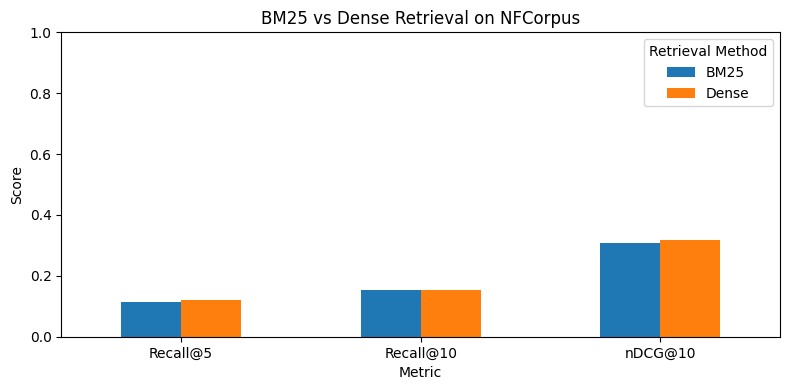

In [ ]:
# Creating a bar chart to compare retrieval scores
# Search time is not included because it uses milliseconds

import matplotlib.pyplot as plt

plot_df = comparison.iloc[:3].set_index("Metric")

ax = plot_df.plot(
    kind="bar",
    figsize=(8, 4),
    rot=0
)

plt.title("BM25 vs Dense Retrieval on NFCorpus")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Retrieval Method")
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "bm25_vs_dense.png",
    dpi=150
)

plt.show()

In [ ]:
# Saving the comparison table for our report

comparison.to_csv(
    RESULTS_DIR / "bm25_vs_dense.csv",
    index=False
)

print("Comparison saved successfully!")

Comparison saved successfully!


In [ ]:
# Downloading the results that we want to keep in GitHub

from google.colab import files

files.download("results/dense_per_query.csv")
files.download("results/dense_summary.csv")
files.download("results/bm25_vs_dense.csv")
files.download("results/bm25_vs_dense.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Checking if BM25 and dense retrieval are working
# before combining them into hybrid search

question = "What are the health benefits of dietary fiber?"

bm25_results = bm25_search(question, top_k=5)
dense_results = dense_search(question, top_k=5)

print("BM25 Results:")
for result in bm25_results:
    print(result["doc_id"], round(result["score"], 4))

print("\nDense Results:")
for result in dense_results:
    print(result["doc_id"], round(result["score"], 4))

BM25 Results:
MED-2291 22.3933
MED-1374 21.6928
MED-973 21.2251
MED-2293 21.181
MED-1234 20.6697

Dense Results:
MED-1234 0.6301
MED-2529 0.6251
MED-2293 0.6017
MED-2291 0.5671
MED-1045 0.5603


In [ ]:
# Combining the ranked results using Reciprocal Rank Fusion
# We use document ranks instead of their original scores

def reciprocal_rank_fusion(bm25_results, dense_results, k=60):

    rrf_scores = {}

    # Adding scores from the BM25 ranking
    for rank, result in enumerate(bm25_results, start=1):

        doc_id = result["doc_id"]

        rrf_scores[doc_id] = (
            rrf_scores.get(doc_id, 0) + 1 / (k + rank)
        )

    # Adding scores from the dense retrieval ranking
    for rank, result in enumerate(dense_results, start=1):

        doc_id = result["doc_id"]

        rrf_scores[doc_id] = (
            rrf_scores.get(doc_id, 0) + 1 / (k + rank)
        )

    # Sorting document IDs based on their final RRF scores
    ranked_docs = sorted(
        rrf_scores.items(),
        key=lambda item: (-item[1], item[0])
    )

    return ranked_docs

In [ ]:
# Testing RRF using a small example
# This helps us understand how the rankings are combined

sample_bm25 = [
    {"doc_id": "A"},
    {"doc_id": "B"},
    {"doc_id": "C"}
]

sample_dense = [
    {"doc_id": "B"},
    {"doc_id": "A"},
    {"doc_id": "D"}
]

fused_results = reciprocal_rank_fusion(
    sample_bm25,
    sample_dense
)

for doc_id, score in fused_results:
    print(doc_id, round(score, 5))

# Both A and B appear in both lists, so they should rank first
assert [item[0] for item in fused_results[:2]] == ["A", "B"]

print("RRF test passed!")

A 0.03252
B 0.03252
C 0.01587
D 0.01587
RRF test passed!


In [ ]:
# Building the hybrid search function
# It combines BM25 and dense retrieval using RRF

def hybrid_search(query, top_k=5, candidate_k=100):

    # Getting candidate documents from both methods
    bm25_results = bm25_search(query, top_k=candidate_k)
    dense_results = dense_search(query, top_k=candidate_k)

    # Combining both rankings
    fused_results = reciprocal_rank_fusion(
        bm25_results,
        dense_results,
        k=60
    )

    results = []

    # Getting the top documents from the combined ranking
    for rank, (doc_id, score) in enumerate(
        fused_results[:top_k],
        start=1
    ):

        results.append({
            "doc_id": doc_id,
            "chunk_id": None,
            "score": float(score),
            "rank": rank,
            "title": corpus[doc_id]["title"],
            "text": corpus[doc_id]["text"]
        })

    return results

In [ ]:
# Testing hybrid search on a sample medical question

question = "Does vitamin D help improve bone health?"

results = hybrid_search(question, top_k=5)

for result in results:

    print("Rank:", result["rank"])
    print("Document ID:", result["doc_id"])
    print("RRF Score:", round(result["score"], 5))
    print("Title:", result["title"])
    print("Text:", result["text"][:200])
    print("-" * 50)

Rank: 1
Document ID: MED-4566
RRF Score: 0.03252
Title: Taking vitamin D with the largest meal improves absorption and results in higher serum levels of 25-hydroxyvitamin D.
Text: Many patients treated for vitamin D deficiency fail to achieve an adequate serum level of 25-hydroxyvitamin D [25(OH)D] despite high doses of ergo- or cholecalciferol. The objective of this study was 
--------------------------------------------------
Rank: 2
Document ID: MED-716
RRF Score: 0.03178
Title: VITAMIN D: A D-LIGHTFUL SOLUTION FOR HEALTH
Text: Throughout evolution sunlight produced vitamin D in the skin has been critically important for health. Vitamin D, known as the sunshine vitamin, is actually a hormone. Once it is produced in the skin 
--------------------------------------------------
Rank: 3
Document ID: MED-1791
RRF Score: 0.03062
Title: A combination of prebiotic short- and long-chain inulin-type fructans enhances calcium absorption and bone mineralization in young adolescents.
Text: BACKG

In [ ]:
# Evaluating hybrid retrieval using the NFCorpus test queries
# We use the same metrics as BM25 and dense retrieval

hybrid_evaluation_results = []

for query_id, relevant_docs in qrels.items():

    if query_id not in queries:
        continue

    question = queries[query_id]

    # Measuring the time for the complete hybrid search
    start_time = time.perf_counter()

    results = hybrid_search(
        question,
        top_k=10,
        candidate_k=100
    )

    search_time = (time.perf_counter() - start_time) * 1000

    retrieved_ids = [
        result["doc_id"]
        for result in results
    ]

    # Calculating evaluation metrics
    hybrid_evaluation_results.append({
        "query_id": query_id,
        "recall_5": recall_at_k(
            retrieved_ids, relevant_docs, 5
        ),
        "recall_10": recall_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "ndcg_10": ndcg_at_k(
            retrieved_ids, relevant_docs, 10
        ),
        "search_time_ms": search_time
    })

hybrid_evaluation_df = pd.DataFrame(
    hybrid_evaluation_results
)

print("Queries evaluated:", len(hybrid_evaluation_df))

display(hybrid_evaluation_df.head())

Queries evaluated: 323


,query_id,recall_5,recall_10,ndcg_10,search_time_ms
0,PLAIN-2,0.166667,0.333333,0.807593,46.827252
1,PLAIN-12,0.000000,0.066667,0.117101,36.095947
2,PLAIN-23,0.033333,0.055556,0.412910,54.958519
3,PLAIN-33,0.000000,0.031250,0.066439,42.726131
4,PLAIN-44,0.017241,0.034483,0.152387,49.113913


In [ ]:
# Calculating the average hybrid retrieval performance

hybrid_summary = hybrid_evaluation_df[
    ["recall_5", "recall_10", "ndcg_10", "search_time_ms"]
].mean()

print("Hybrid Retrieval Results")
print("------------------------")

print("Recall@5:", round(hybrid_summary["recall_5"], 4))
print("Recall@10:", round(hybrid_summary["recall_10"], 4))
print("nDCG@10:", round(hybrid_summary["ndcg_10"], 4))
print(
    "Average search time:",
    round(hybrid_summary["search_time_ms"], 2),
    "ms"
)

Hybrid Retrieval Results
------------------------
Recall@5: 0.1289
Recall@10: 0.161
nDCG@10: 0.3353
Average search time: 36.26 ms


In [ ]:
# Comparing BM25, dense, and hybrid retrieval
# The summary variables are from our previous experiments

comparison_df = pd.DataFrame({
    "Metric": [
        "Recall@5",
        "Recall@10",
        "nDCG@10",
        "Search Time (ms)"
    ],
    "BM25": [
        summary["recall_5"],
        summary["recall_10"],
        summary["ndcg_10"],
        summary["search_time_ms"]
    ],
    "Dense": [
        dense_summary["recall_5"],
        dense_summary["recall_10"],
        dense_summary["ndcg_10"],
        dense_summary["search_time_ms"]
    ],
    "Hybrid": [
        hybrid_summary["recall_5"],
        hybrid_summary["recall_10"],
        hybrid_summary["ndcg_10"],
        hybrid_summary["search_time_ms"]
    ]
})

display(comparison_df.round(4))

,Metric,BM25,Dense,Hybrid
0,Recall@5,0.1150,0.1197,0.1289
1,Recall@10,0.1521,0.1550,0.1610
2,nDCG@10,0.3071,0.3169,0.3353
3,Search Time (ms),16.9960,26.0708,36.2638


In [ ]:
# Checking that the evaluations used the same query IDs
# This is important for making a fair comparison

bm25_query_ids = set(evaluation_df["query_id"])
dense_query_ids = set(dense_evaluation_df["query_id"])
hybrid_query_ids = set(hybrid_evaluation_df["query_id"])

assert bm25_query_ids == dense_query_ids
assert dense_query_ids == hybrid_query_ids

print("All three methods used the same test queries!")

All three methods used the same test queries!


In [ ]:
# Saving results from the hybrid retrieval experiment

hybrid_evaluation_df.to_csv(
    RESULTS_DIR / "hybrid_per_query.csv",
    index=False
)

hybrid_summary_df = hybrid_summary.reset_index()
hybrid_summary_df.columns = ["metric", "value"]

hybrid_summary_df.to_csv(
    RESULTS_DIR / "hybrid_summary.csv",
    index=False
)

print("Hybrid evaluation results saved!")

Hybrid evaluation results saved!


In [ ]:
# Saving the comparison of all three retrieval methods

comparison_df.to_csv(
    RESULTS_DIR / "retrieval_comparison.csv",
    index=False
)

print("Retrieval comparison saved!")

Retrieval comparison saved!


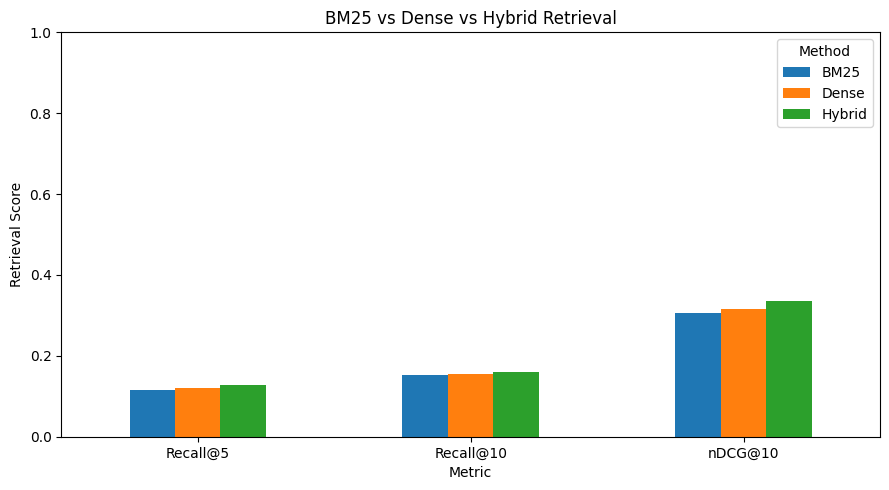

In [ ]:
# Plotting the retrieval scores for all three methods
# Search time is excluded because it uses milliseconds

import matplotlib.pyplot as plt

plot_data = comparison_df.iloc[:3].set_index("Metric")

ax = plot_data.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

plt.title("BM25 vs Dense vs Hybrid Retrieval")
plt.ylabel("Retrieval Score")
plt.ylim(0, 1)
plt.legend(title="Method")

plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "retrieval_comparison.png",
    dpi=150
)

plt.show()